# EDA（fujise）

In [2]:
import matplotlib.pyplot as plt
import matplotlib_fontja  # グラフで日本語を表示する
import numpy as np
import pandas as pd
import seaborn as sns

TARGET = "取引価格（総額）"

# 面積は "45" と "2,000㎡以上" が混ざっていて、数値と文字列が混在した列になるので、文字列でそろえる
train = pd.read_csv("../utokyo-mlapp-2026-ex1/train.csv", dtype={"面積（㎡）": str})
test = pd.read_csv("../utokyo-mlapp-2026-ex1/test.csv", dtype={"面積（㎡）": str})
train.shape, test.shape


((202323, 20), (29341, 19))

## 取引価格（総額）× 取引時期

`取引時期` は「2019年第1四半期」のような文字列なので、グラフの x 軸に使えるように数値（年 + 四半期の端数）に直す。

In [3]:
period = train["取引時期"].str.extract(r"(\d{4})年第(\d)四半期").astype(int)
train["時期_数値"] = period[0] + (period[1] - 1) / 4
train[["取引時期", "時期_数値"]].drop_duplicates().sort_values("時期_数値").head()


,取引時期,時期_数値
80,2019年第1四半期,2019.00
29,2019年第2四半期,2019.25
14,2019年第3四半期,2019.50
39,2019年第4四半期,2019.75
7,2020年第1四半期,2020.00


### 散布図

そのまま描くと、20 万件の点が 26 本の縦線に重なり、価格の幅も広すぎて読めない。そこで次のようにする。

- y 軸を対数目盛りにする
- 点を半透明にし、x を少し左右にばらす（ジッター）
- 四半期ごとの中央値を線で重ねる

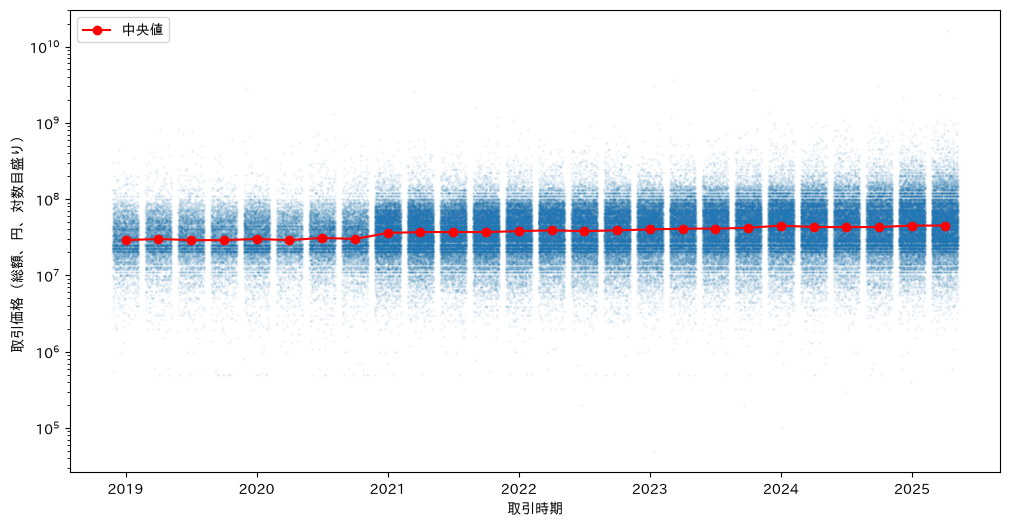

In [ ]:
rng = np.random.default_rng(0)
jitter = rng.uniform(-0.1, 0.1, len(train))
median = train.groupby("時期_数値")[TARGET].median()

fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(train["時期_数値"] + jitter, train[TARGET], s=1, alpha=0.05)
ax.plot(median.index, median.values, color="red", marker="o", label="中央値")
ax.set_yscale("log")
ax.set_xlabel("取引時期")
ax.set_ylabel("取引価格（総額、円、対数目盛り）")
ax.legend()
plt.show()


### 四半期ごとの箱ひげ図

散布図では分かりにくい、ばらつきの変化を比べる。

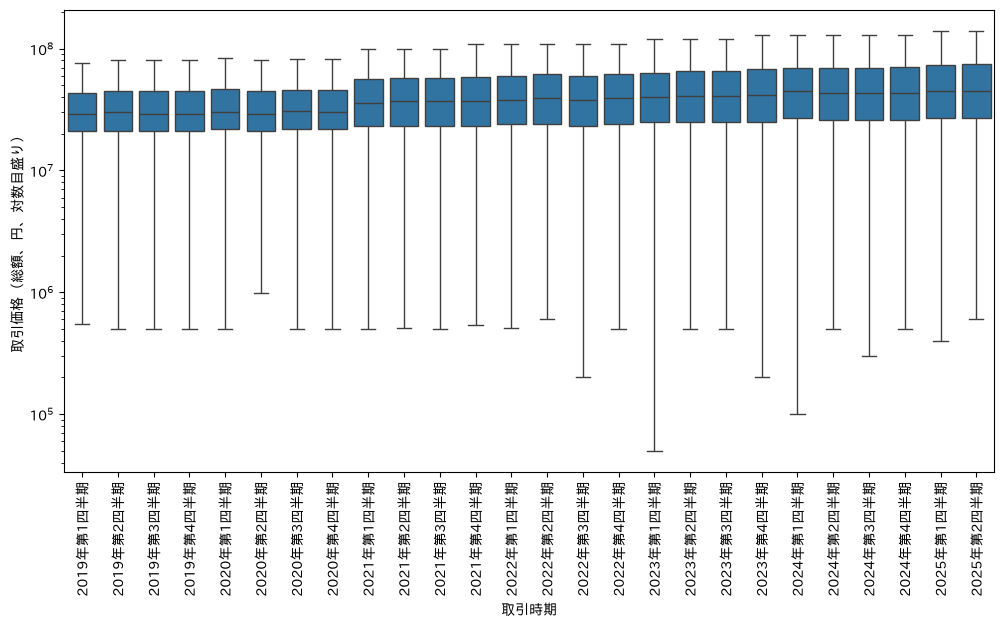

In [5]:
order = train.sort_values("時期_数値")["取引時期"].unique()

fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=train, x="取引時期", y=TARGET, order=order, showfliers=False, ax=ax)
ax.set_yscale("log")
ax.set_ylabel("取引価格（総額、円、対数目盛り）")
ax.tick_params(axis="x", rotation=90)
plt.show()


## 全カラムの分布

各カラムがどんな値をどれくらいの割合で持つかを整理する。値の種類の数に合わせて、グラフを使い分ける。

- 種類が少ないカテゴリ変数: 円グラフ
- 種類が多いカテゴリ変数（市区町村名・地区名・最寄駅）: 件数の多い順の横棒グラフ
- 数値として扱える列（面積・建築年・駅距離・価格）: ヒストグラム

`id` は行番号なので見ない。`市区町村コード` は `市区町村名` と 1 対 1 なので、名前の方だけ見る。

### 概要と欠損率

In [6]:
summary = pd.DataFrame(
    {
        "型": train.dtypes.astype(str),
        "種類数": train.nunique(),
        "欠損数": train.isna().sum(),
        "欠損率": train.isna().mean().round(3),
    }
).drop(columns=["時期_数値"], errors="ignore")
summary


,型,種類数,欠損数,欠損率
id,int64,202323,0,0.000
価格情報区分,str,2,0,0.000
市区町村コード,int64,51,0,0.000
市区町村名,str,51,0,0.000
地区名,str,1210,0,0.000
最寄駅：名称,str,630,1470,0.007
最寄駅：距離（分）,str,34,3561,0.018
取引価格（総額）,int64,296,0,0.000
間取り,str,48,6004,0.030
面積（㎡）,str,87,0,0.000


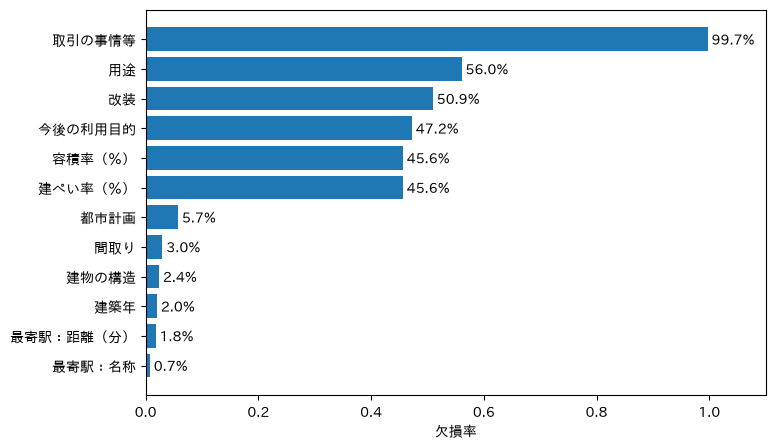

In [7]:
missing = train.isna().mean().sort_values()
missing = missing[missing > 0]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(missing.index, missing.values)
for i, v in enumerate(missing.values):
    ax.text(v, i, f" {v:.1%}", va="center")
ax.set_xlim(0, 1.1)
ax.set_xlabel("欠損率")
plt.show()


### 種類が少ないカテゴリ変数（円グラフ）

欠損も 1 つの値として扱い、割合を見る。小さい値まで全部描くとラベルが重なるので、上位 7 種類に入らない値と割合が 1.5% 未満の値は「上位以外」にまとめる（`用途` などにはもともと「その他」という値があるので、名前を分けている）。まとめた中身は次のセルの表で確認する。

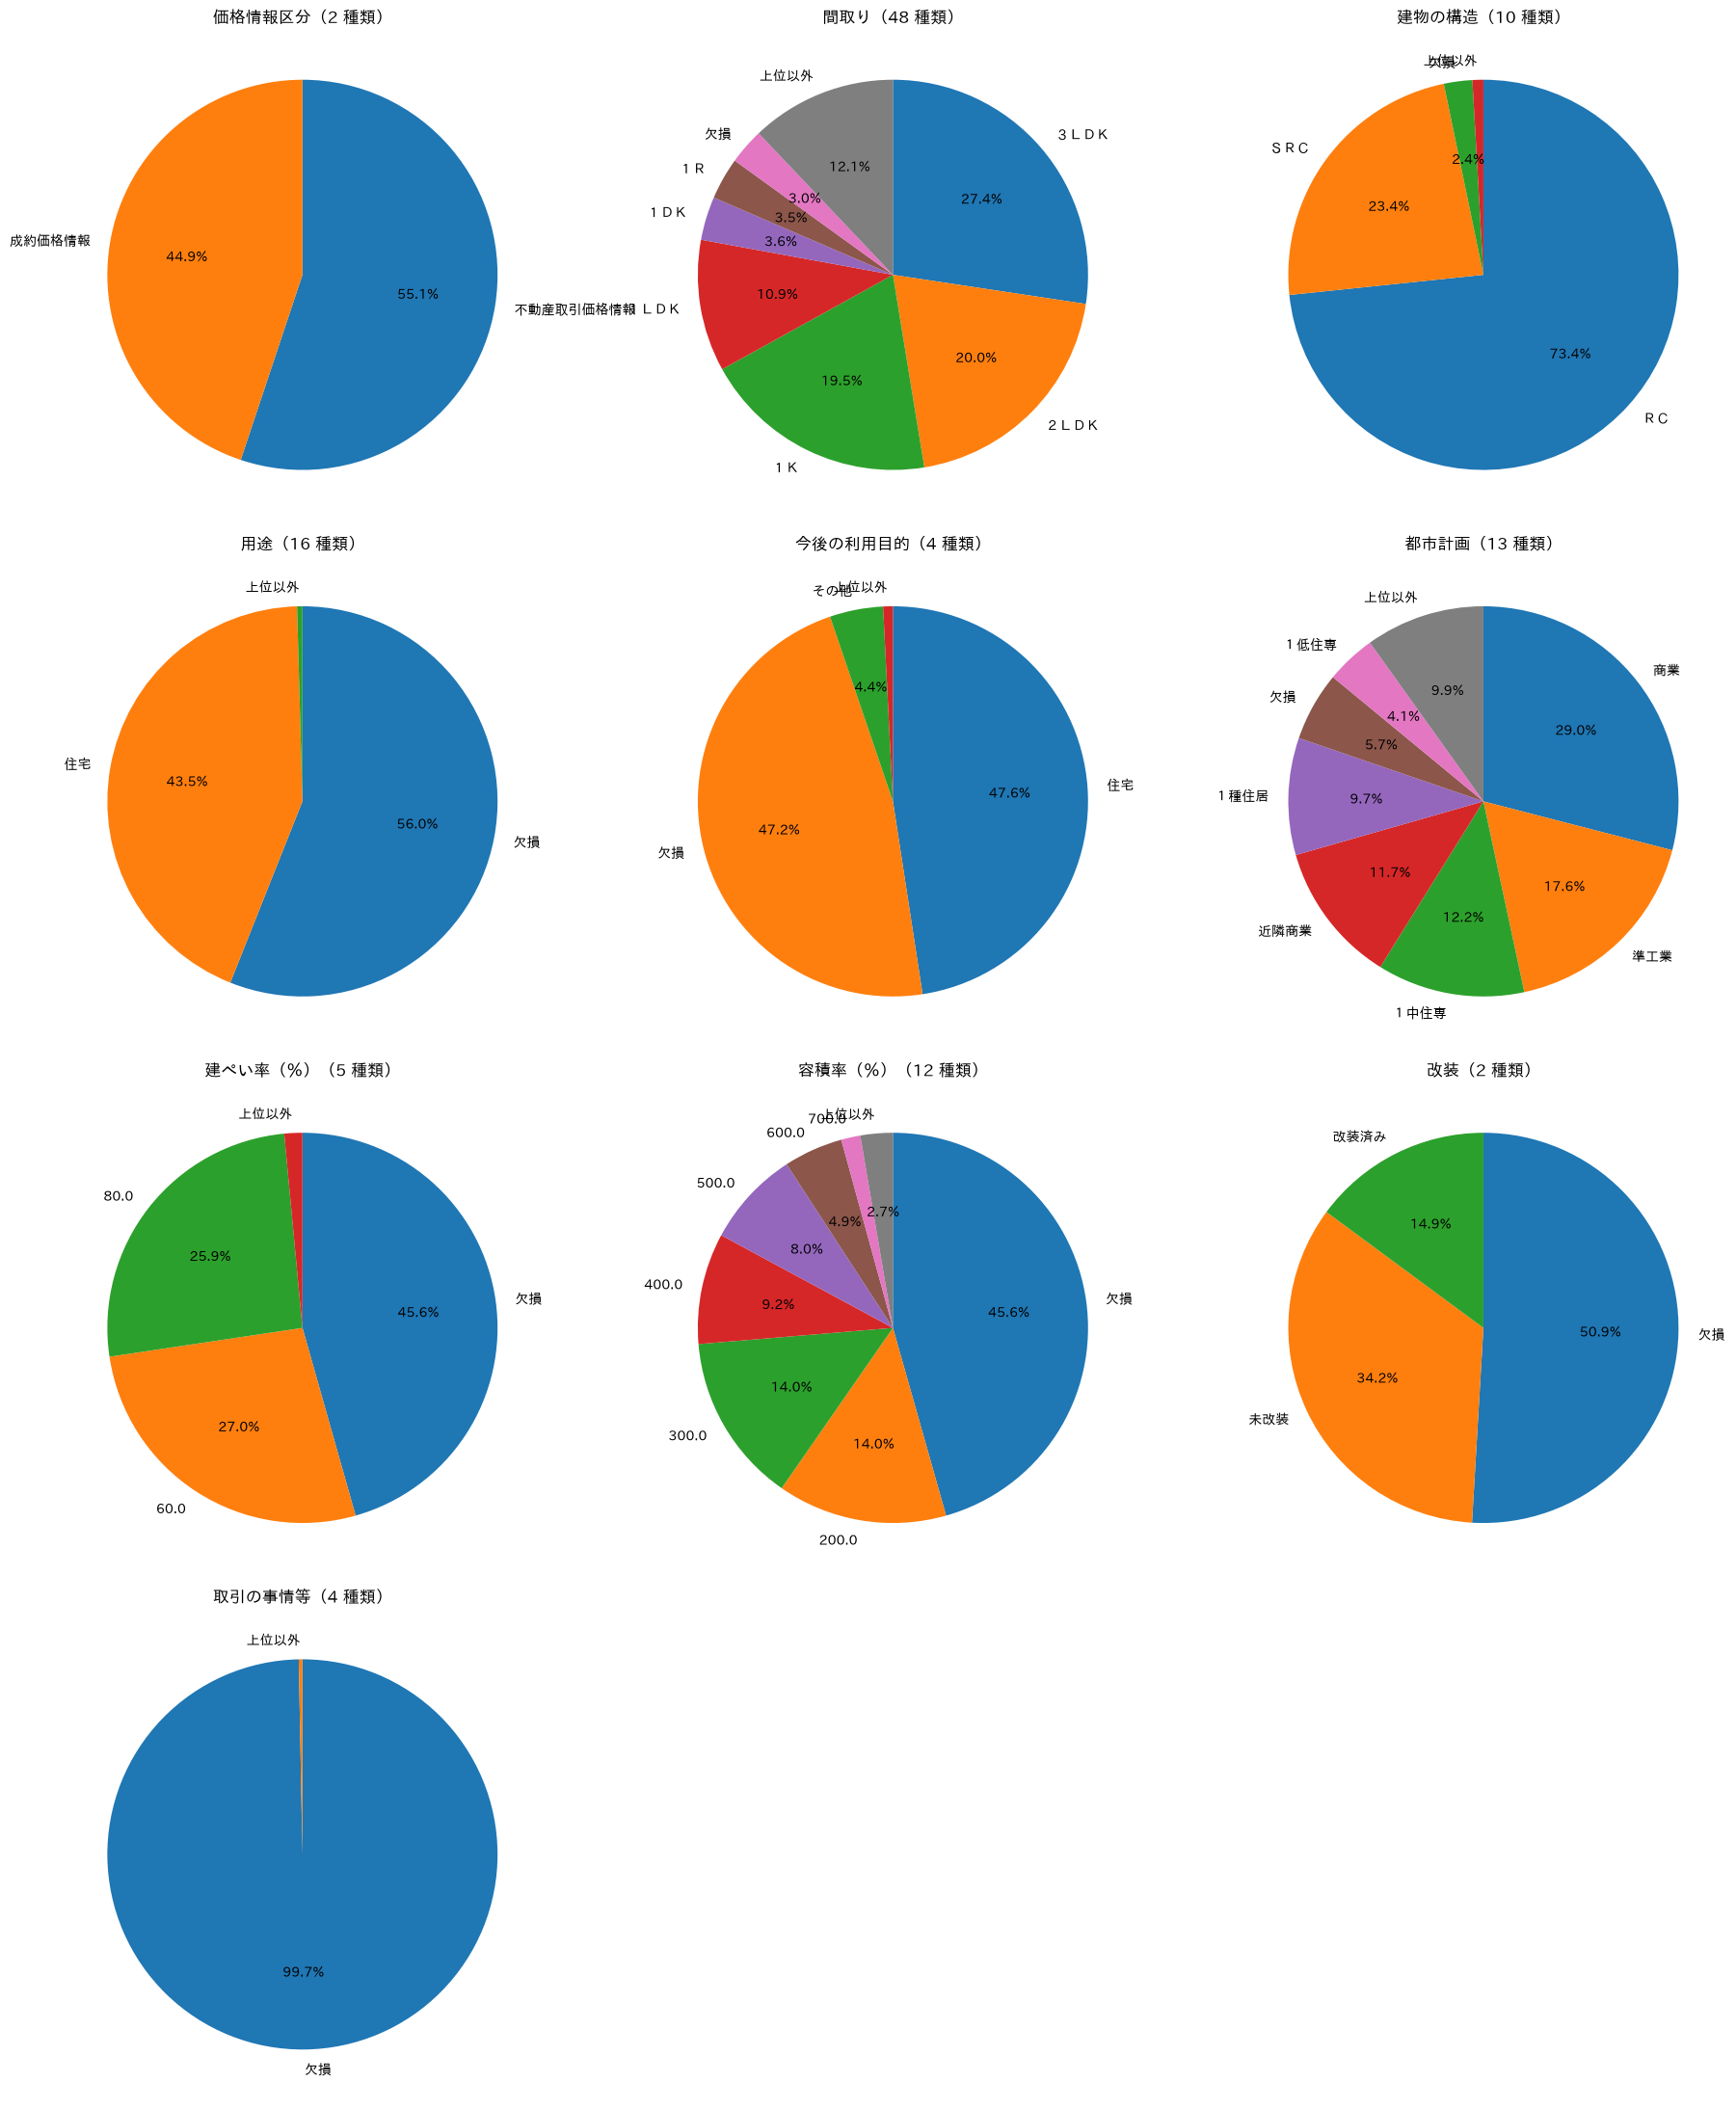

In [ ]:
PIE_COLS = [
    "価格情報区分",
    "間取り",
    "建物の構造",
    "用途",
    "今後の利用目的",
    "都市計画",
    "建ぺい率（％）",
    "容積率（％）",
    "改装",
    "取引の事情等",
]


def value_share(s, top=7, min_share=0.015):
    counts = s.fillna("欠損").astype(str).value_counts()
    keep = (counts.reset_index(drop=True).index < top) & (counts.values / counts.sum() >= min_share)
    if (~keep).sum() > 1:
        counts = pd.concat([counts[keep], pd.Series({"上位以外": counts[~keep].sum()})])
    return counts


fig, axes = plt.subplots(4, 3, figsize=(18, 22))
for ax, col in zip(axes.flat, PIE_COLS):
    counts = value_share(train[col])
    ax.pie(
        counts.values,
        labels=counts.index,
        autopct=lambda p: f"{p:.1f}%" if p >= 2 else "",
        startangle=90,
        counterclock=False,
    )
    ax.set_title(f"{col}（{train[col].nunique()} 種類）")
for ax in axes.flat[len(PIE_COLS):]:
    ax.axis("off")
plt.tight_layout()
plt.show()


円グラフでは細かい値が見えないので、件数と割合を表でも出しておく。

In [9]:
for col in PIE_COLS:
    counts = train[col].value_counts(dropna=False)
    display(pd.DataFrame({"件数": counts, "割合": (counts / len(train)).round(4)}).rename_axis(col))


,件数,割合
価格情報区分,,
不動産取引価格情報,111526,0.5512
成約価格情報,90797,0.4488


,件数,割合
間取り,,
３ＬＤＫ,55408,0.2739
２ＬＤＫ,40547,0.2004
１Ｋ,39525,0.1954
１ＬＤＫ,22091,0.1092
１ＤＫ,7280,0.0360
１Ｒ,7026,0.0347
NaN,6004,0.0297
２ＤＫ,5956,0.0294
４ＬＤＫ,5373,0.0266


,件数,割合
建物の構造,,
ＲＣ,148409,0.7335
ＳＲＣ,47328,0.2339
NaN,4763,0.0235
鉄骨造,1535,0.0076
ＳＲＣ、ＲＣ,132,0.0007
軽量鉄骨造,64,0.0003
ＲＣ、鉄骨造,54,0.0003
木造,17,0.0001
ＳＲＣ、鉄骨造,15,0.0001


,件数,割合
用途,,
NaN,113353,0.5603
住宅,88075,0.4353
事務所,365,0.0018
店舗,252,0.0012
その他,180,0.0009
事務所、店舗,32,0.0002
駐車場,26,0.0001
倉庫,14,0.0001
住宅、事務所,10,0.0000


,件数,割合
今後の利用目的,,
住宅,96246,0.4757
NaN,95512,0.4721
その他,8934,0.0442
事務所,1261,0.0062
店舗,370,0.0018


,件数,割合
都市計画,,
商業,58731,0.2903
準工業,35624,0.1761
１中住専,24740,0.1223
近隣商業,23673,0.1170
１種住居,19623,0.0970
NaN,11570,0.0572
１低住専,8368,0.0414
２種住居,6952,0.0344
工業,4792,0.0237


,件数,割合
建ぺい率（％）,,
NaN,92273,0.4561
60.0,54693,0.2703
80.0,52339,0.2587
50.0,2437,0.0120
40.0,554,0.0027
30.0,27,0.0001


,件数,割合
容積率（％）,,
NaN,92273,0.4561
200.0,28426,0.1405
300.0,28363,0.1402
400.0,18615,0.0920
500.0,16090,0.0795
600.0,9923,0.0490
700.0,3222,0.0159
150.0,2745,0.0136
100.0,1479,0.0073


,件数,割合
改装,,
NaN,103045,0.5093
未改装,69176,0.3419
改装済み,30102,0.1488


,件数,割合
取引の事情等,,
NaN,201714,0.9970
調停・競売等,516,0.0026
関係者間取引,87,0.0004
その他事情有り,3,0.0000
瑕疵有りの可能性,3,0.0000


### 種類が多いカテゴリ変数（横棒グラフ）

`地区名`（約 1,200 種類）と `最寄駅：名称`（約 600 種類）は全部は描けないので、上位 30 件だけ描く。

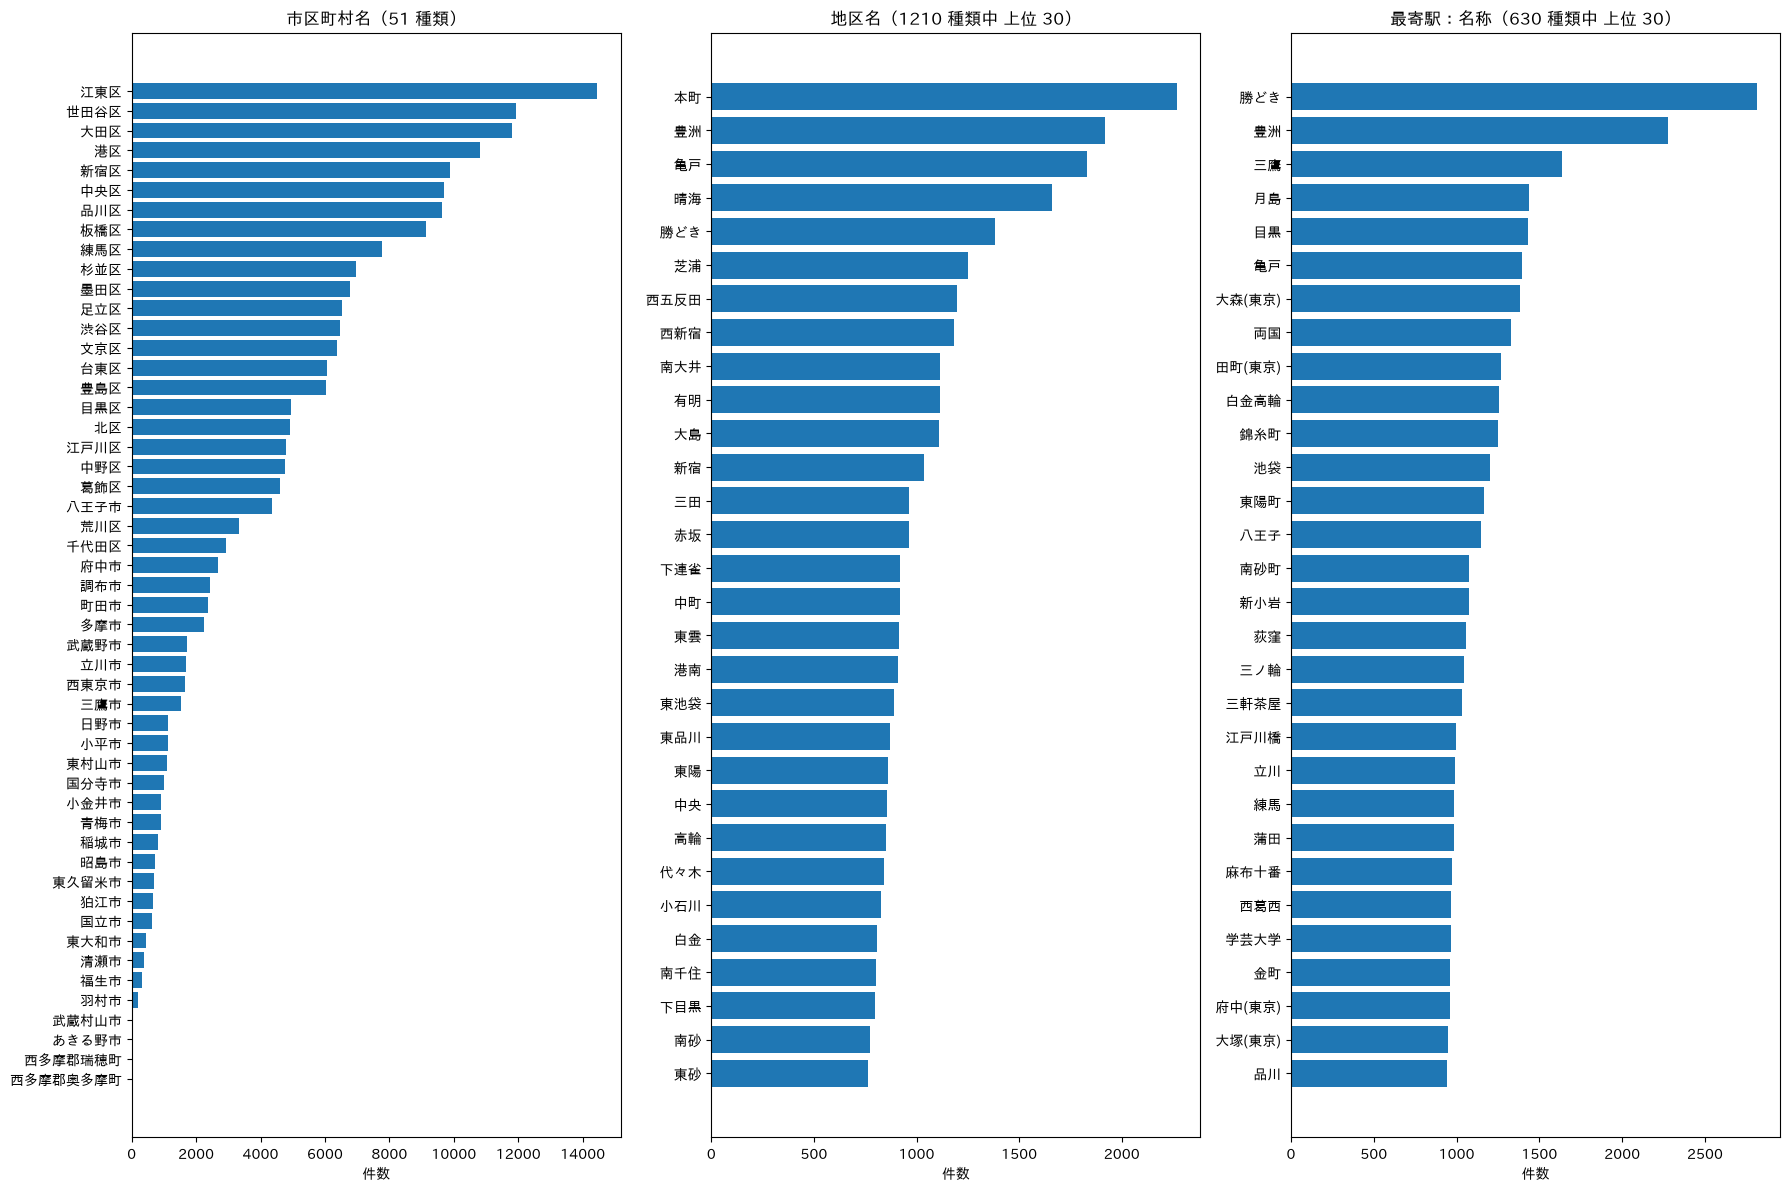

In [ ]:
BAR_COLS = {"市区町村名": None, "地区名": 30, "最寄駅：名称": 30}

fig, axes = plt.subplots(1, 3, figsize=(18, 12))
for ax, (col, top) in zip(axes, BAR_COLS.items()):
    counts = train[col].value_counts()
    shown = counts if top is None else counts.iloc[:top]
    ax.barh(shown.index[::-1], shown.values[::-1])
    title = f"{col}（{len(counts)} 種類）" if top is None else f"{col}（{len(counts)} 種類中 上位 {top}）"
    ax.set_title(title)
    ax.set_xlabel("件数")
plt.tight_layout()
plt.show()


上位の数件に偏っているのか、広く薄く散らばっているのかを見るため、上位 k 種類で全体の何割を占めるか（累積割合）も描く。

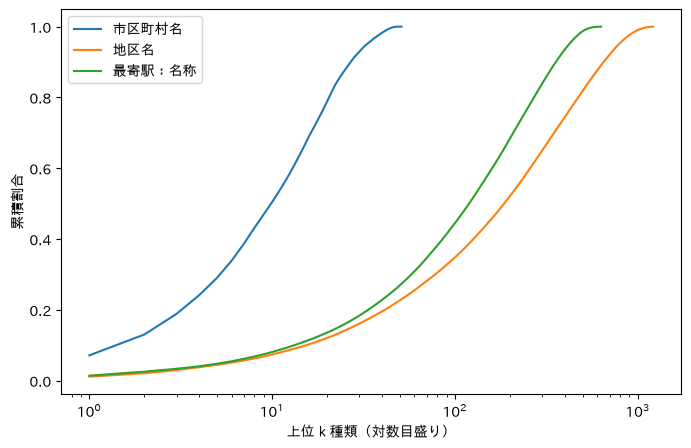

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
for col in BAR_COLS:
    share = train[col].value_counts(normalize=True).cumsum().reset_index(drop=True)
    ax.plot(share.index + 1, share.values, label=col)
ax.set_xscale("log")
ax.set_xlabel("上位 k 種類（対数目盛り）")
ax.set_ylabel("累積割合")
ax.legend()
plt.show()


### 数値として扱える列（ヒストグラム）

次の列は文字列が混ざっているので、数値に直してから描く。

- `面積（㎡）`: 「2,000㎡以上」を 2000 にする
- `建築年`: 「〇〇年」から数字を取り出す。「戦前」は数値にできないので件数だけ出す
- `最寄駅：距離（分）`: 30 分以上は「30分～60分」のような幅のある値しかないので、数値にせず順番をそろえた棒グラフにする

面積 2,000㎡以上: 1 件
建築年 戦前: 21 件


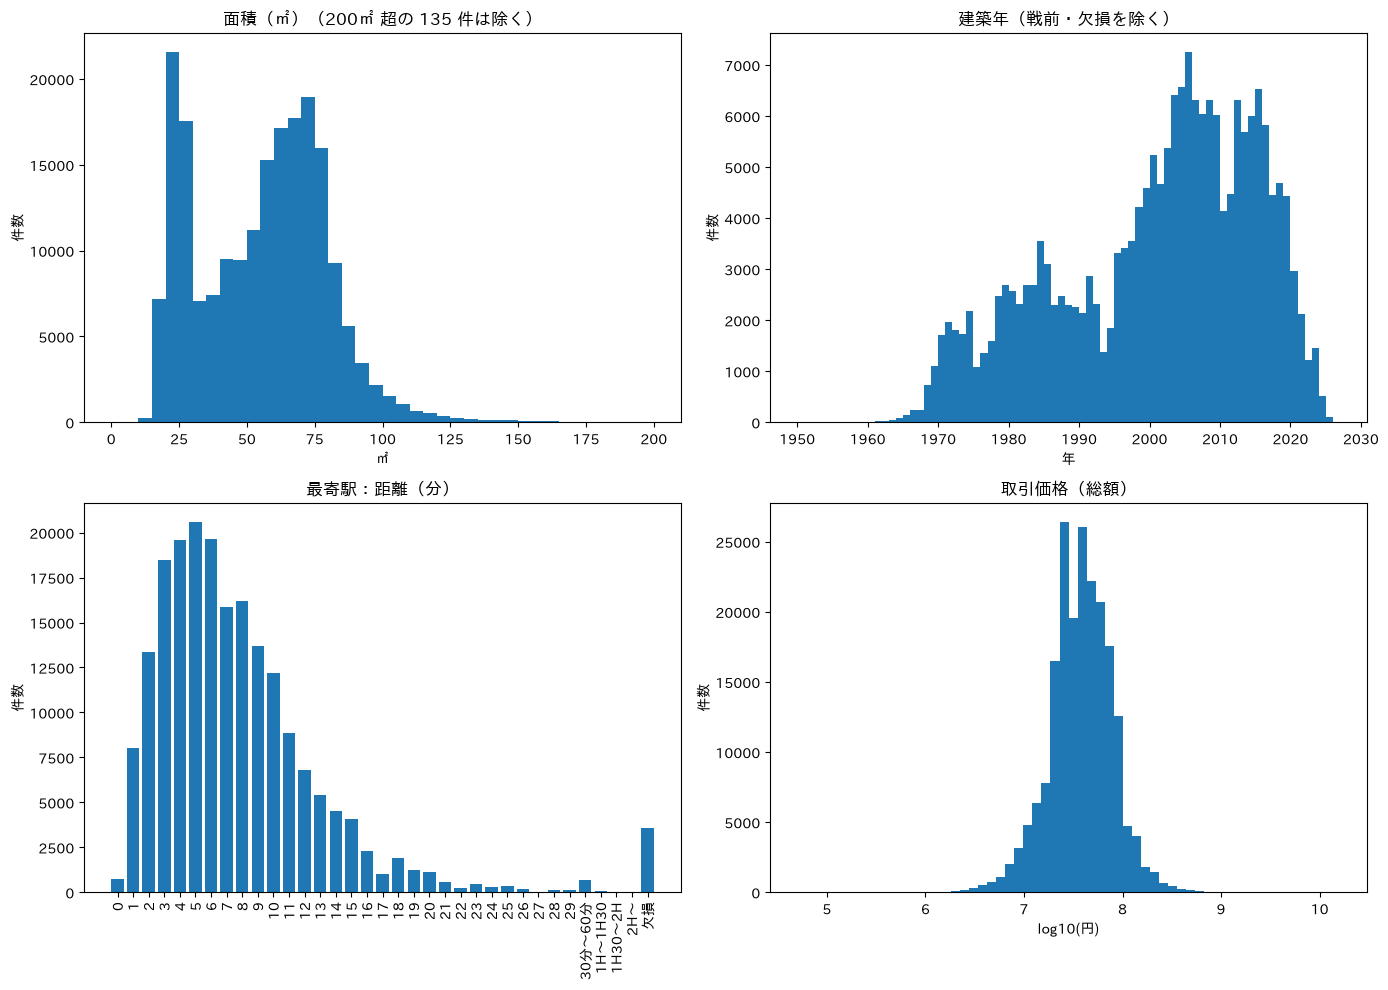

In [12]:
area = pd.to_numeric(train["面積（㎡）"].str.replace("2,000㎡以上", "2000"))
built = pd.to_numeric(train["建築年"].str.extract(r"(\d{4})年")[0])
print("面積 2,000㎡以上:", (area >= 2000).sum(), "件")
print("建築年 戦前:", (train["建築年"] == "戦前").sum(), "件")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 面積は 5㎡ 刻みの値しかないので、ビンもそれに合わせる。200㎡ を超える物件はごく少ないので切る
ax = axes[0, 0]
ax.hist(area[area <= 200], bins=range(0, 205, 5))
ax.set_title(f"面積（㎡）（200㎡ 超の {(area > 200).sum()} 件は除く）")
ax.set_xlabel("㎡")

ax = axes[0, 1]
ax.hist(built.dropna(), bins=range(int(built.min()), int(built.max()) + 2))
ax.set_title("建築年（戦前・欠損を除く）")
ax.set_xlabel("年")

ax = axes[1, 0]
dist = train["最寄駅：距離（分）"].fillna("欠損").value_counts()
dist_order = sorted([k for k in dist.index if k.isdigit()], key=int) + [
    "30分～60分",
    "1H～1H30",
    "1H30～2H",
    "2H～",
    "欠損",
]
dist_order = [k for k in dist_order if k in dist.index]
ax.bar(dist_order, dist[dist_order].values)
ax.set_title("最寄駅：距離（分）")
ax.tick_params(axis="x", rotation=90)

ax = axes[1, 1]
ax.hist(np.log10(train[TARGET]), bins=60)
ax.set_title(TARGET)
ax.set_xlabel("log10(円)")

for ax in axes.flat:
    ax.set_ylabel("件数")
plt.tight_layout()
plt.show()


### 取引時期ごとの件数

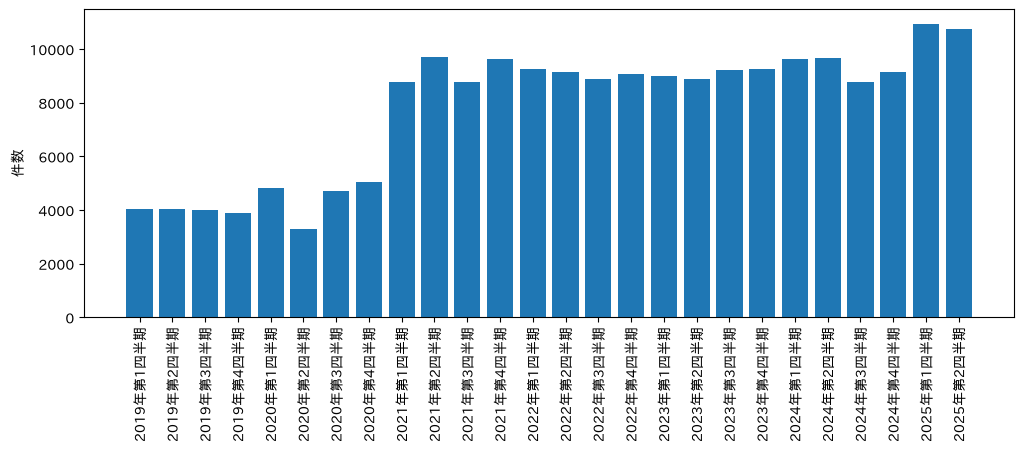

In [13]:
counts = train["取引時期"].value_counts().reindex(order)

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(counts.index, counts.values)
ax.set_ylabel("件数")
ax.tick_params(axis="x", rotation=90)
plt.show()
